In [135]:
url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
titanic = pd.read_csv(url)


In [136]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [137]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Cabin          687
Embarked         2
dtype: int64

In [138]:
titanic = titanic.drop(columns=["Cabin"])

In [139]:
titanic.isnull().sum()

PassengerId      0
Survived         0
Pclass           0
Name             0
Sex              0
Age            177
SibSp            0
Parch            0
Ticket           0
Fare             0
Embarked         2
dtype: int64

In [140]:
mean_age = titanic["Age"].mean()
titanic["Age"] = titanic["Age"].fillna(mean_age)

In [141]:
titanic.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       2
dtype: int64

In [142]:
titanic = titanic.dropna(subset=["Embarked"])

In [143]:
titanic.isnull().sum()

PassengerId    0
Survived       0
Pclass         0
Name           0
Sex            0
Age            0
SibSp          0
Parch          0
Ticket         0
Fare           0
Embarked       0
dtype: int64

In [144]:
titanic.groupby("Sex")["Survived"].mean()

Sex
female    0.740385
male      0.188908
Name: Survived, dtype: float64

In [145]:
titanic.groupby("Pclass")["Survived"].mean()

Pclass
1    0.626168
2    0.472826
3    0.242363
Name: Survived, dtype: float64

<Axes: xlabel='Pclass,Sex'>

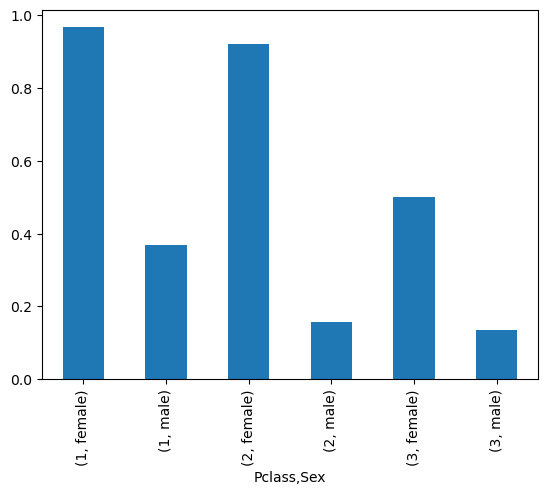

In [146]:
titanic.groupby(["Pclass", "Sex"])["Survived"].mean().plot(kind="bar")

In [147]:
titanic["Sex"] = titanic["Sex"].map({"female": 1, "male": 0})

In [148]:
titanic.head()

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",0,22.0,1,0,A/5 21171,7.2500,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",1,38.0,1,0,PC 17599,71.2833,C
2,3,1,3,"Heikkinen, Miss. Laina",1,26.0,0,0,STON/O2. 3101282,7.9250,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",1,35.0,1,0,113803,53.1000,S
4,5,0,3,"Allen, Mr. William Henry",0,35.0,0,0,373450,8.0500,S


In [149]:
features = ["Pclass", "Sex", "Age", "Fare"]
X = titanic[features]
y = titanic["Survived"]

In [150]:
X.head()

,Pclass,Sex,Age,Fare
0,3,0,22.0,7.2500
1,1,1,38.0,71.2833
2,3,1,26.0,7.9250
3,1,1,35.0,53.1000
4,3,0,35.0,8.0500


In [151]:
y.head()

0    0
1    1
2    1
3    1
4    0
Name: Survived, dtype: int64

In [152]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [153]:
print("تعداد داده‌های آموزش:", len(X_train))
print("تعداد داده‌های تست:", len(X_test))

تعداد داده‌های آموزش: 711
تعداد داده‌های تست: 178


In [154]:
print("تعداد کل داده‌ها:", len(titanic))

تعداد کل داده‌ها: 889


In [155]:
from sklearn.tree import DecisionTreeClassifier
model = DecisionTreeClassifier()

In [156]:
model.fit(X_train, y_train)

,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [157]:
predictions = model.predict(X_test)

In [158]:
from sklearn.tree import DecisionTreeClassifier

# ۱. ساخت مدل
model = DecisionTreeClassifier()

# ۲. آموزش مدل با داده‌های Train
model.fit(X_train, y_train)

# ۳. پیش‌بینی روی داده‌های Test
predictions = model.predict(X_test)

In [159]:
print(predictions[:10])

[0 1 1 0 1 0 0 0 1 1]


In [160]:
# ۱۰ تای اول از داده‌های تست رو کپی می‌کنیم
sample = X_test.head(10).copy()

# ستون پیش‌بینی مدل رو اضافه می‌کنیم
sample["Predicted"] = predictions[:10]

# ستون جواب واقعی رو هم می‌ذاریم کنارش تا مقایسه کنیم!
sample["Actual"] = y_test.head(10).values

sample


,Pclass,Sex,Age,Fare,Predicted,Actual
281,3,0,28.0,7.8542,0,0
435,1,1,14.0,120.0000,1,1
39,3,1,14.0,11.2417,1,1
418,2,0,30.0,13.0000,0,0
585,1,1,18.0,79.6500,1,1
804,3,0,27.0,6.9750,0,1
343,2,0,25.0,13.0000,0,0
836,3,0,21.0,8.6625,0,0
581,1,1,39.0,110.8833,1,1
537,1,1,30.0,106.4250,1,1


In [161]:
from sklearn.metrics import accuracy_score

print(accuracy_score(y_test, predictions))

0.7584269662921348


In [162]:
X = titanic[["Pclass", "Sex", "Age", "Fare", "SibSp", "Parch"]]
y = titanic["Survived"]

In [163]:
X.head()

,Pclass,Sex,Age,Fare,SibSp,Parch
0,3,0,22.0,7.2500,1,0
1,1,1,38.0,71.2833,1,0
2,3,1,26.0,7.9250,0,0
3,1,1,35.0,53.1000,1,0
4,3,0,35.0,8.0500,0,0


In [164]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

In [165]:
model = DecisionTreeClassifier()
model.fit(X_train, y_train)


,criterion,'gini'
,splitter,'best'
,max_depth,None
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,None
,random_state,None
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,class_weight,None


In [166]:
predictions = model.predict(X_test)

print(accuracy_score(y_test, predictions))


0.7696629213483146


In [167]:
# این بار به درخت می‌گیم عمقش بیشتر از 3 نشه
smart_model = DecisionTreeClassifier(max_depth=3)

smart_model.fit(X_train, y_train)

smart_preds = smart_model.predict(X_test)

print(accuracy_score(y_test, smart_preds))


0.8202247191011236


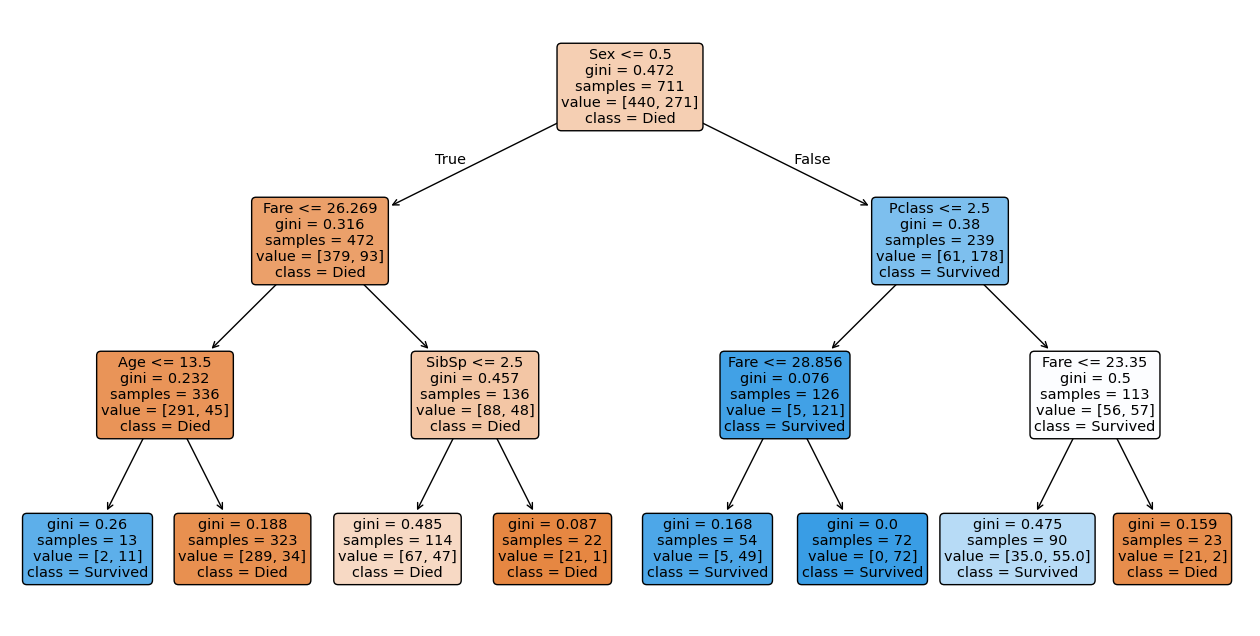

In [168]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# تنظیم اندازه تصویر که بزرگ و خوانا باشه
plt.figure(figsize=(16, 8))

# کشیدن شکل درخت
plot_tree(
    smart_model,
    feature_names=X.columns,
    class_names=["Died", "Survived"],
    filled=True,
    rounded=True,
)

plt.show()
